# COU 07506 — Digital Signal Processing

## Week 1: Lab 0 — Setting Up the DSP Laboratory

**Name:** [SALIMIN BURUHANI SHECHONGE]  
**Registration Number:** 240242411437  
**Group:** 1  
**Date:** [1/11/2026]

### Task 1.1 — Your First Notebook

The aim of this task is to create and plot basic discrete-time signals using Python and Google Colab.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

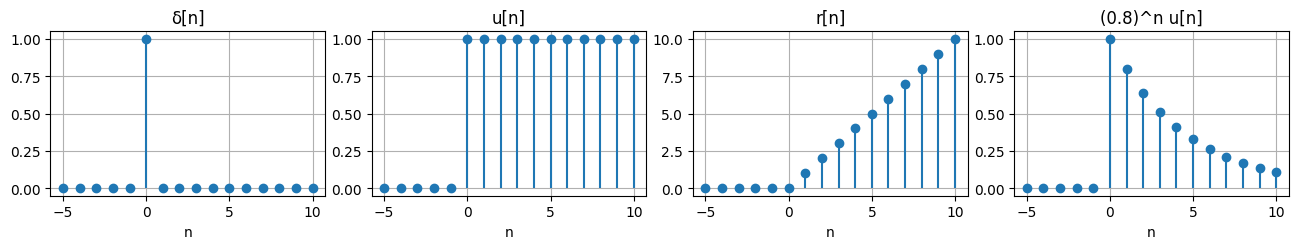

In [ ]:
n = np.arange(-5, 11)

delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = np.maximum(n, 0).astype(float)
expo = 0.8**n * step

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

titles = ["δ[n]", "u[n]", "r[n]", "(0.8)^n u[n]"]
signals = [delta, step, ramp, expo]

for ax, title, x in zip(axes, titles, signals):
    ax.stem(n, x, basefmt=" ")
    ax.set_title(title)
    ax.set_xlabel("n")
    ax.grid(True)

plt.tight_layout()
plt.show()

## Task 1.2 — Change the Parameters

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

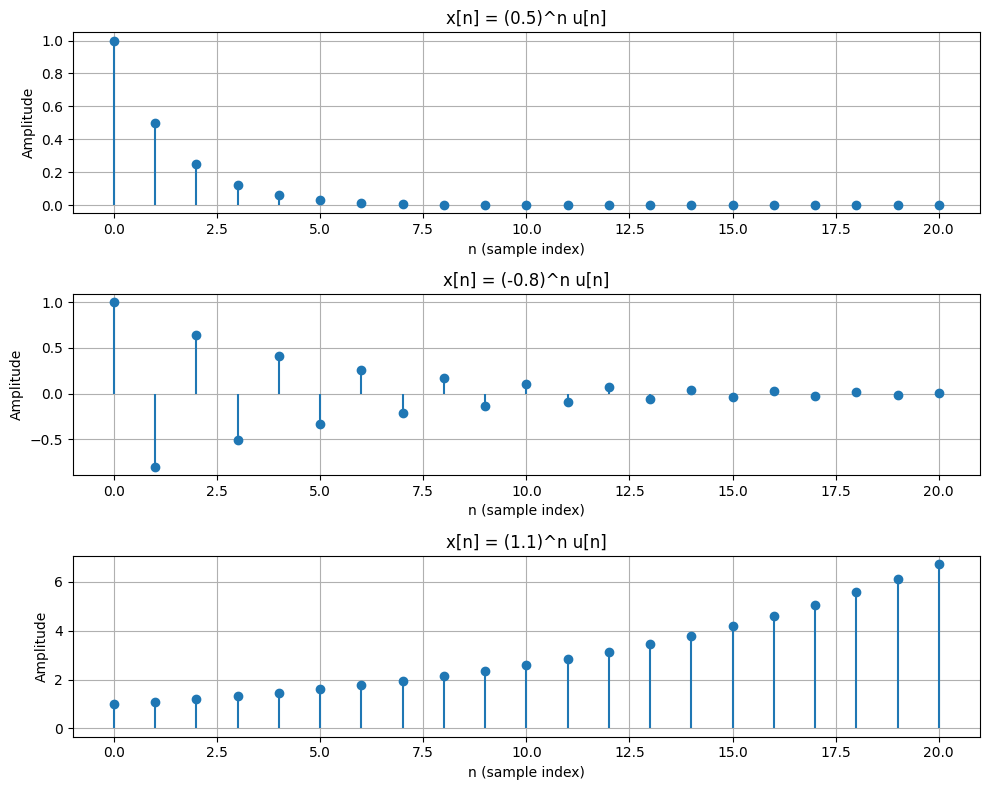

In [3]:
n = np.arange(0, 21)

a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(3, 1, figsize=(10, 8))

for ax, a in zip(axes, a_values):
    x = (a**n) * (n >= 0)
    ax.stem(n, x, basefmt=" ")
    ax.set_title(f"x[n] = ({a})^n u[n]")
    ax.set_xlabel("n (sample index)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()

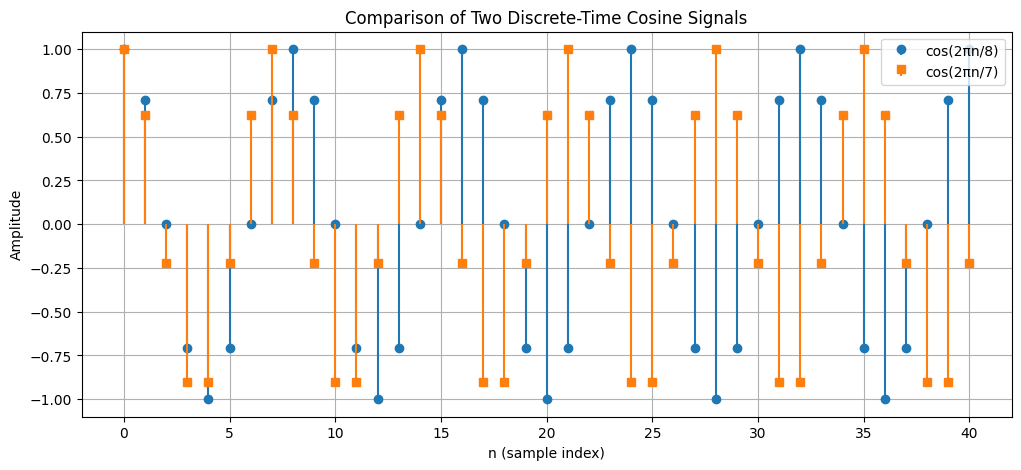

In [4]:
n = np.arange(0, 41)

x1 = np.cos(2 * np.pi * n / 8)
x2 = np.cos(2 * np.pi * n / 7)

plt.figure(figsize=(12, 5))

plt.stem(n, x1, linefmt="C0-", markerfmt="C0o",
         basefmt=" ", label="cos(2πn/8)")
plt.stem(n, x2, linefmt="C1-", markerfmt="C1s",
         basefmt=" ", label="cos(2πn/7)")

plt.title("Comparison of Two Discrete-Time Cosine Signals")
plt.xlabel("n (sample index)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

Task 1.3 — Working with audio

fs = 16000 Hz, duration = 2.00 s, samples = 32000


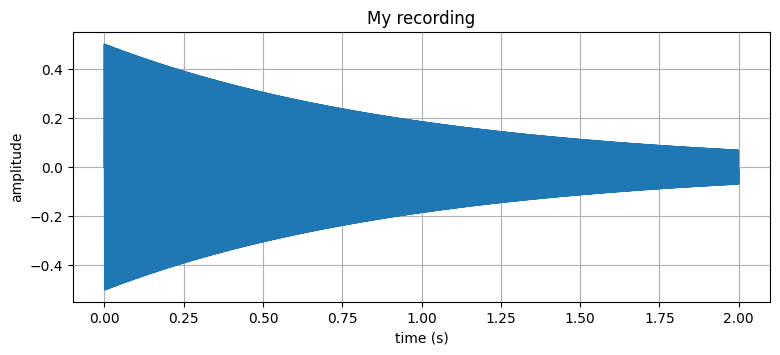

In [5]:
import os
fname = "my_voice.wav"                # change to your file name
if os.path.exists(fname):
    fs, x = wavfile.read(fname)       # fs = sampling rate, x = samples
    if x.ndim > 1:                    # stereo -> mono
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))         # normalise to [-1, 1]
else:                                 # fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)

t = np.arange(len(x)) / fs            # time axis in seconds
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x); plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("My recording"); plt.grid(True); plt.show()

In [6]:
from IPython.display import Audio
Audio(x, rate=fs)